In [2]:

import matplotlib.gridspec as gridspec
import os
import sys

import scipy.stats
import umap
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder
from BWM.models.isometric_autoencoder import get_density_proxy
active_lambda = 0.1 # Default value if not imported
sys.path.append(os.path.abspath('../../'))
from BWM.ScriptsandFunctions.bwm_functions import *
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [11]:
def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    #row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    #X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_transposed


directory_path='../Data2'
eids = [d for d in os.listdir(directory_path) if os.path.isdir(os.path.join(directory_path, d))]
# result = get_region_response_matrix(
#                 region=['MOs','MOp'],
#                 eids=eids,
#                 directory_path=directory_path,
#                 event="stimOn_times",
#                 conditions=['choice'],
#                 n_pseudo=25,
#                 threshold=5,
#                 std_above=50,
#                 std_below=50,
#                 filter_significant=False,
#                 n_steps=100,
#                 step=0.01,
#                 sigma=2,
#                 mapping='Beryl'
#             )
# pseudo_response_tensor =result[0]
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
#pseudo_response_tensor = pseudo_response_tensor[:,:,:,np.mean(pseudo_response_tensor,axis=(0,1,2))<15]
#
# selected_eid = '6274dda8-3a59-4aa1-95f8-a8a549c46a26' # Example EID
# directory_path = '../Data2'
# event = 'stimOn_times'
# conditions = ['choice']
#
# result = get_eid_response_matrix(
#     selected_eid, directory_path, event, conditions,
#     n_pseudo=25,
#     threshold = 0,
#
#     filter_significant=False,
#     n_steps=100, step=0.01 , sigma=2,
# )
#
#
# pseudo_response_tensor, common_conditions, beryl_regions, cosmos_regions, cluster_ids = result


In [12]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    Input shape: (conditions, time, neurons) OR (n_pseudo, conditions, time, neurons)
    Returns: (neurons,) array
    """
    # Z-score: (response - mean) / (std + eps)
    # The axes (0, 1) in the original code assume (conditions, time, neurons)
    # If the input is (n_pseudo, conditions, time, neurons), axis=(0, 1, 2) should be used for Z-scoring
    # and the mean firing rate/standard deviation calculation.

    # Let's handle both 3D and 4D cases and make it more robust.
    if response_tensor.ndim == 4:
        # (n_pseudo, conditions, time, neurons)
        z = (response_tensor - np.mean(response_tensor, axis=(0, 1, 2), keepdims=True)) / (np.std(response_tensor, axis=(0, 1, 2), keepdims=True) + 1e-8)
        # diff along time axis (axis=2)
        speed = np.mean(np.abs(np.diff(z, axis=2)), axis=(0, 1, 2))
    else:
        # (conditions, time, neurons)
        z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
        # diff along time axis (axis=1)
        speed = np.mean(np.abs(np.diff(z, axis=1)), axis=(0, 1))

    return speed


def calculate_msd_gradient_autograd(X, n_conditions=2, n_time=100):
    """
    Calculate the magnitude of the gradient of the MSD formula with respect to the activity X,
    projected onto the tangent space of the hypersphere (since each neuron's activity is normalized to unit length).
    Uses torch autograd for exact gradient computation.
    X: (n_neurons, n_conditions * n_time)
    """
    X_torch = torch.tensor(X, dtype=torch.float32, requires_grad=True)

    # Reshape to (n_neurons, n_conditions, n_time)
    # The preprocessing reshaped (C, T, N) -> (C*T, N) -> (N, C*T)
    z = X_torch.view(X_torch.shape[0], n_conditions, n_time)

    # MSD formula: mean absolute temporal difference
    # diff along time axis (dim=2)
    diffs = torch.abs(z[:, :, 1:] - z[:, :, :-1])
    msd_per_neuron = torch.mean(diffs, dim=(1, 2))

    grad_magnitudes = []
    for i in range(X_torch.shape[0]):
        # Compute gradient of MSD_i with respect to X_i
        if X_torch.grad is not None:
            X_torch.grad.zero_()

        msd_per_neuron[i].backward(retain_graph=True)
        grad = X_torch.grad[i]

        # Current position on the sphere (normalized neuron activity)
        x_i = X_torch[i].detach()

        # Project gradient onto the tangent space of the unit sphere at x_i
        # g_proj = g - (g . x) * x
        dot_product = torch.dot(grad, x_i)
        grad_tangent = grad - dot_product * x_i

        grad_magnitudes.append(torch.norm(grad_tangent).item())

    return np.array(grad_magnitudes)

Computing densMAP projection for Figure 2...


/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/matplotlib/patches.py:3421: RuntimeWarning: invalid value encountered in scalar divide
  cos_t, sin_t = head_length / head_dist, head_width / head_dist


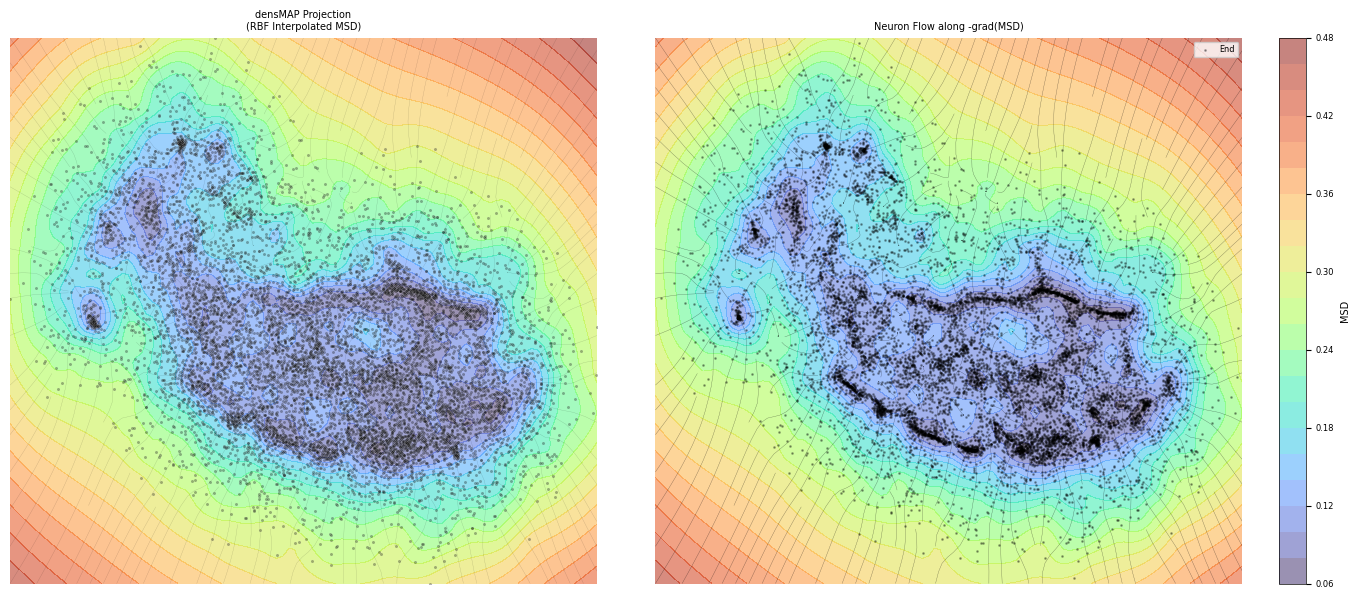

In [31]:

X = iso_ae_preprocessing(pseudo_response_tensor)
avg_response = np.mean(pseudo_response_tensor, axis=0)
msd_grad_target = calculate_msd_gradient_autograd(X, n_conditions=avg_response.shape[0], n_time=avg_response.shape[1])
density_proxy_target = get_density_proxy(X, k=min(10, X.shape[0]-1)).numpy()
corr_grad_target, p_val_grad_target = pearsonr(density_proxy_target, msd_grad_target)

fig2 = plt.figure(figsize=(14, 6))

# 1. 2D densMAP projection colored by RBF interpolation of MSD
print("Computing densMAP projection for Figure 2...")
#reducer = umap.UMAP(densmap=True, dens_lambda=2, n_neighbors=2000)

#proj = reducer.fit_transform(X)

# Handle potential NaNs or Infs from UMAP
if not np.all(np.isfinite(proj)):
    print("Warning: NaNs or Infs detected in densMAP projection. Filling with zeros.")
    proj = np.nan_to_num(proj)

# Re-calculate MSD for the target EID to ensure consistency
msd_target_vals = calculate_msd_data(avg_response)

ax2_msd2d = fig2.add_subplot(1, 2, 1)
x_min, x_max = proj[:, 0].min(), proj[:, 0].max()
y_min, y_max = proj[:, 1].min(), proj[:, 1].max()

# Ensure non-zero range and equal spacing for streamplot
if x_min == x_max: x_max += 1e-6
if y_min == y_max: y_max += 1e-6

xi = np.linspace(x_min, x_max, 100)
yi = np.linspace(y_min, y_max, 100)

# Enforce strict equal spacing for matplotlib streamplot
xi = x_min + np.arange(100) * (x_max - x_min) / 99
yi = y_min + np.arange(100) * (y_max - y_min) / 99

XI, YI = np.meshgrid(xi, yi)

#rbf_msd = Rbf(proj[:, 0], proj[:, 1], msd_target_vals, function='multiquadric', smooth=10)
ZI_msd = rbf_msd(XI, YI)

# Calculate numerical gradient for streamlines
dy, dx = np.gradient(ZI_msd, yi[1] - yi[0], xi[1] - xi[0])

cont = ax2_msd2d.contourf(XI, YI, ZI_msd, levels=20, cmap='turbo', alpha=.5)
strm = ax2_msd2d.streamplot(xi, yi, -dx, -dy, color='k', linewidth=0.25, density=1.5, arrowsize=0)
strm.lines.set_alpha(0.2)
sns.scatterplot(x=proj[:, 0], y=proj[:, 1], color='k', s=5, alpha=0.3, ax=ax2_msd2d)
cb = plt.colorbar(cont, ax=ax2_msd2d, label='MSD')
cb.ax.set_visible(False)
ax2_msd2d.set_title('densMAP Projection\n(RBF Interpolated MSD)')
ax2_msd2d.set_xticks([])
ax2_msd2d.set_yticks([])
sns.despine(ax=ax2_msd2d, left=True, bottom=True)

# 2. Flow neurons along the negative gradient
ax2_3 = fig2.add_subplot(1, 2, 2)

# Use the numerical gradients computed earlier (dx, dy) on the grid (xi, yi)
# to interpolate the gradient at each neuron's position in 'proj'
from scipy.interpolate import RegularGridInterpolator

# RegularGridInterpolator expects points as (y_grid, x_grid) if indices are [iy, ix]
# In our case, ZI_msd is [yi, xi]
interp_grad_x = RegularGridInterpolator((yi, xi), -dx, bounds_error=False, fill_value=None)
interp_grad_y = RegularGridInterpolator((yi, xi), -dy, bounds_error=False, fill_value=None)

# Original positions
pts = proj.copy()

# Flow parameters
dt = .005  # Step size
n_steps = 300

# Store trajectories for plotting
trajectories = [pts.copy()]

# Replace any potential NaNs in starting positions
if np.any(np.isnan(pts)):
    print("Warning: NaNs detected in project points. Filling with mean.")
    col_mean = np.nanmean(pts, axis=0)
    inds = np.where(np.isnan(pts))
    pts[inds] = np.take(col_mean, inds[1])

curr_pts = pts.copy()
for _ in range(n_steps):
    # Clip points to stay within grid bounds for interpolation
    # Use bounds_error=False to be more robust to precision issues,
    # but we still clip to keep points within the meaningful range.
    curr_pts[:, 0] = np.clip(curr_pts[:, 0], xi[0], xi[-1])
    curr_pts[:, 1] = np.clip(curr_pts[:, 1], yi[0], yi[-1])

    # Handle potential NaNs that might arise during flow
    curr_pts = np.nan_to_num(curr_pts, nan=0.0)

    # Get negative gradient at current positions
    # RegularGridInterpolator expects (y, x) order if we passed (yi, xi)
    g_x = interp_grad_x(curr_pts[:, [1, 0]])
    g_y = interp_grad_y(curr_pts[:, [1, 0]])

    # Update positions (flowing along negative gradient)
    curr_pts[:, 0] += g_x * dt
    curr_pts[:, 1] += g_y * dt
    trajectories.append(curr_pts.copy())

# Plotting the flow
cont_flow = ax2_3.contourf(XI, YI, ZI_msd, levels=20, cmap='turbo', alpha=.5)
strm_flow = ax2_3.streamplot(xi, yi, -dx, -dy, color='k', linewidth=0.25, density=1.5, arrowsize=0)
strm_flow.lines.set_alpha(0.5)

ax2_3.scatter(curr_pts[:, 0], curr_pts[:, 1], color='k', s=1, alpha=0.3, label='End')

plt.colorbar(cont_flow, ax=ax2_3, label='MSD')
ax2_3.set_title('Neuron Flow along -grad(MSD)')
ax2_3.set_xticks([])
ax2_3.set_yticks([])
ax2_3.legend(loc='upper right', fontsize='small')
sns.despine(ax=ax2_3, left=True, bottom=True)

plt.tight_layout()
plt.savefig(f'../Figures/Individual_EID_Correlations/msd_gradient_correlation.png', dpi=150)
plt.show()
